|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[15] Analogy vectors</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import pandas as pd
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

from transformers import RobertaTokenizer, RobertaForMaskedLM

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':50,
})

# **Part 1: Explore the RoBERTa model**

In [3]:
tokenizer = RobertaTokenizer.from_pretrained('roberta-large')
model = RobertaForMaskedLM.from_pretrained('roberta-large')
model.eval()

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

RobertaForMaskedLM(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
              (

In [4]:
# extract the embeddings matrix
embeddings = model.roberta.embeddings.word_embeddings.weight.detach().numpy()
embeddings.shape

(50265, 1024)

In [5]:
words = [ 'list', 'computer', 'apple', 'spaceship' ]

for w in words:
  print(f'"{w}" is indices {tokenizer.encode(w)}')
  print(f'" {w}" is indices {tokenizer.encode(" "+w)}\n')

"list" is indices [0, 8458, 2]
" list" is indices [0, 889, 2]

"computer" is indices [0, 36327, 2]
" computer" is indices [0, 3034, 2]

"apple" is indices [0, 27326, 2]
" apple" is indices [0, 15162, 2]

"spaceship" is indices [0, 4182, 11667, 4128, 2]
" spaceship" is indices [0, 39881, 2]



In [6]:
for i in range(20):
  print(f'Index {i:2} is "{tokenizer.decode(i)}"')

Index  0 is "<s>"
Index  1 is "<pad>"
Index  2 is "</s>"
Index  3 is "<unk>"
Index  4 is "."
Index  5 is " the"
Index  6 is ","
Index  7 is " to"
Index  8 is " and"
Index  9 is " of"
Index 10 is " a"
Index 11 is " in"
Index 12 is "-"
Index 13 is " for"
Index 14 is " that"
Index 15 is " on"
Index 16 is " is"
Index 17 is "�"
Index 18 is "'s"
Index 19 is " with"


In [7]:
print(tokenizer.encode([' king'],add_special_tokens=False))
print(tokenizer.encode(' king',add_special_tokens=False))

[[8453]]
[8453]


# **Part 2: Extract four embeddings and make a dataframe**

In [8]:
# tokenize
words = [ ' king',' man',' woman',' queen' ]
tokens = [tokenizer.encode(w,add_special_tokens=False) for w in words]

# print the token indices and corresponding tokens (words)
for w,tok in zip(words,tokens):
  print(f'"{w}" is encoded using token indices {tok}')

" king" is encoded using token indices [8453]
" man" is encoded using token indices [313]
" woman" is encoded using token indices [693]
" queen" is encoded using token indices [12133]


In [9]:
# although we actually need a list of ints, not a list of lists of ints
tokens = [t[0] for t in tokens]
tokens

[8453, 313, 693, 12133]

In [10]:
# submatrix with embeddings
E = embeddings[tokens]
df = pd.DataFrame(E.T,columns=words)

# summary of dataframe
df.describe()

,king,man,woman,queen
count,1024.000000,1024.000000,1024.000000,1024.000000
mean,-0.014800,-0.009457,-0.008126,-0.014895
std,0.118443,0.111115,0.106411,0.127133
min,-0.283936,-0.291992,-0.251221,-0.329590
25%,-0.101105,-0.101608,-0.092102,-0.110809
50%,-0.017754,-0.015762,-0.011028,-0.020470
75%,0.067276,0.070145,0.073578,0.078506
max,0.298828,0.280273,0.272949,0.302490


# **Part 3: Visualize using pairplots**

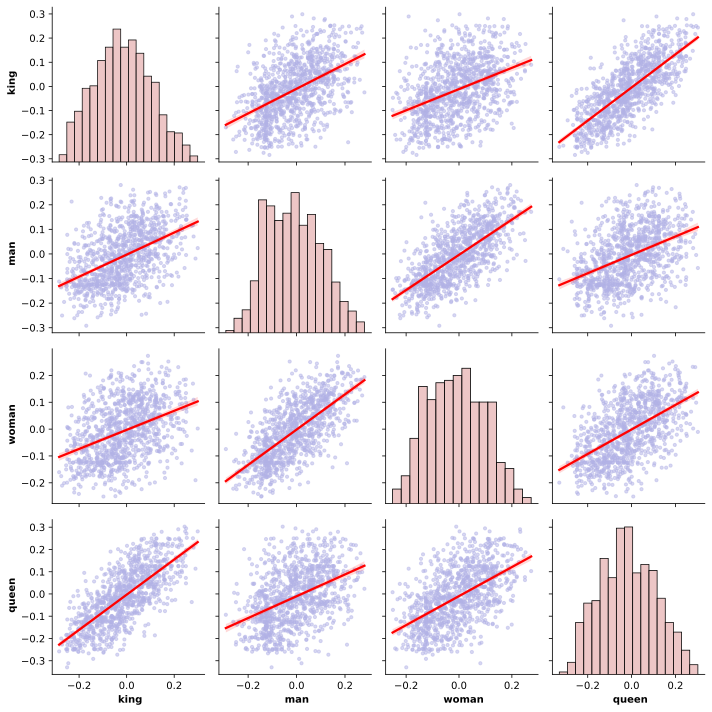

In [11]:
# visualize
sns.pairplot(df,kind='reg',
             plot_kws={'line_kws':{'color':'r'},
                       'scatter_kws':{'color':[.7,.7,.9],'s':10,'alpha':.5}},
             diag_kws={'color':[.9,.7,.7]}
            )

plt.tight_layout()
plt.savefig('ch3_proj15_part3.png')
plt.show()

# **Part 4: Visualize cosine similarities**

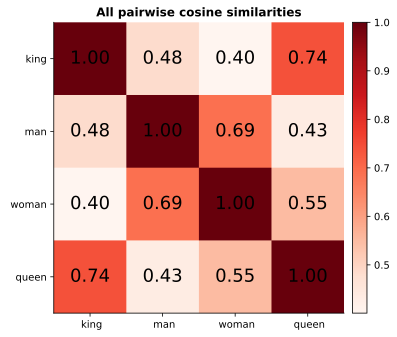

In [12]:
# cosine similarities
csMat = cosine_similarity(E)

# show the matrix
plt.imshow(csMat,vmin=csMat.min(),vmax=1,cmap='Reds')
plt.gca().set(xticks=range(4),yticks=range(4),
              xticklabels=words,yticklabels=words,
              title='All pairwise cosine similarities')

# add text labels
for i in range(4):
  for j in range(4):
    plt.text(j,i,f'{csMat[i,j]:.2f}',
             ha='center',va='center',fontsize=18)

plt.colorbar(pad=.02)

plt.tight_layout()
plt.savefig('ch3_proj15_part4.png')
plt.show()

# **Part 5: Arithmetic with embeddings vectors**

In [13]:
# king - man + woman
analogyVector = df[' king'] - df[' man'] + df[' woman']
sim2all = cosine_similarity(analogyVector.values.reshape(1,-1),embeddings)
sim2all = np.squeeze(sim2all)

fig = plt.figure(figsize=(12,3.5))
gs = gridspec.GridSpec(1,3,figure=fig)
ax1 = fig.add_subplot(gs[:-1])
ax2 = fig.add_subplot(gs[-1])

ax1.scatter(range(len(sim2all)),sim2all,
            c=np.sqrt(abs(sim2all)),alpha=.7,s=(sim2all**2)*60,cmap='cool')
ax1.set(xlabel='Token index',ylabel='Cosine similarity',
        title='A) Cosine similarity with analogy vector')

ax2.hist(sim2all,bins='fd',color=[.7,.7,.9],edgecolor='gray')
ax2.set(xlabel='Cosine similarity',ylabel='Count',
        xlim=[sim2all.min(),sim2all.max()],yscale='log',
        title='B) Distribution of similarities')

plt.tight_layout()
plt.savefig('ch3_proj15_part5.png')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [14]:
# print out the top 10 highest scores
top10 = sim2all.argsort()[-10:][::-1]

print(' CosSim  |   R^2   |    word')
print('---------+---------+-------------')
for widx in top10:
  # correlation (square it to get shared variance)
  r = np.corrcoef(analogyVector,embeddings[widx])[0,1]
  print(f'  {sim2all[widx]:.3f}  |  {100*r**2:4.1f}%  |  "{tokenizer.decode(widx)}"')

 CosSim  |   R^2   |    word
---------+---------+-------------
  0.784  |  61.1%  |  " king"
  0.715  |  50.7%  |  " queen"
  0.604  |  35.9%  |  " King"
  0.600  |  35.5%  |  " Queen"
  0.589  |  34.1%  |  " princess"
  0.566  |  31.6%  |  " kings"
  0.564  |  31.5%  |  " woman"
  0.558  |  30.5%  |  " monarch"
  0.549  |  29.7%  |  " queens"
  0.545  |  29.3%  |  " women"


# **Part 6: An analogy-completing function**

In [15]:
def analogyCalculator(word2start,word2subtract,word2add):

  # 1) print the analogy
  print(f'"{word2start}" is to "{word2subtract}" as "_____" is to "{word2add}"\n')

  # 2) tokenize the words
  tokens = [tokenizer.encode(w,add_special_tokens=False) for w in [word2start,word2subtract,word2add]]

  # 3) check that each word is one token
  if sum([len(l) for l in tokens]) != 3:
    raise ValueError("Warning: too many tokens.")

  # transform into single list
  tokens = [t[0] for t in tokens]

  if '<unk>' in tokenizer.decode(tokens):
    raise ValueError("Unknown token: ",tokenizer.decode(tokens))

  # 4) get the vectors
  v1 = embeddings[tokens[0]] # base word
  v2 = embeddings[tokens[1]] # to subtract
  v3 = embeddings[tokens[2]] # to add

  # 5) analogy vector
  analogyVector = v1 - v2 + v3

  # 6) cossim with all
  cossim2all = cosine_similarity(analogyVector.reshape(1,-1),embeddings)[0]

  # 7) print out the top 10 highest scores
  top10 = cossim2all.argsort()[-10:][::-1]
  print('  CosSim  |   R^2   |    word')
  print('----------+---------+-------------')
  for widx in top10:
    # correlation (square it to get shared variance)
    r = np.corrcoef(analogyVector,embeddings[widx])[0,1]
    print(f'  {cossim2all[widx]:6.3f}  |  {100*r**2:4.1f}%  |  "{tokenizer.decode(widx)}"')


In [16]:
# try it
analogyCalculator(' king',' man',' woman')

" king" is to " man" as "_____" is to " woman"

  CosSim  |   R^2   |    word
----------+---------+-------------
   0.784  |  61.1%  |  " king"
   0.715  |  50.7%  |  " queen"
   0.604  |  35.9%  |  " King"
   0.600  |  35.5%  |  " Queen"
   0.589  |  34.1%  |  " princess"
   0.566  |  31.6%  |  " kings"
   0.564  |  31.5%  |  " woman"
   0.558  |  30.5%  |  " monarch"
   0.549  |  29.7%  |  " queens"
   0.545  |  29.3%  |  " women"


In [17]:
# analogyCalculator(' tree',' leaf',' petals')
# analogyCalculator('tree','leaf','petals')
# analogyCalculator('leaf','tree','flower') # turn it around for better results?
# analogyCalculator(' husky',' dog',' bird')
# analogyCalculator('finger','hand','foot')
# analogyCalculator(' shoe',' foot',' hand')
analogyCalculator(' hand',' glove',' shoe')
# analogyCalculator('tomorrow','future','past')
# analogyCalculator('pants','legs','arms')

" hand" is to " glove" as "_____" is to " shoe"

  CosSim  |   R^2   |    word
----------+---------+-------------
   0.634  |  40.1%  |  " hand"
   0.623  |  38.8%  |  " shoe"
   0.435  |  18.8%  |  " shoes"
   0.418  |  17.4%  |  " Hand"
   0.415  |  17.0%  |  " hands"
   0.403  |  16.1%  |  " foot"
   0.389  |  15.0%  |  "hand"
   0.379  |  14.2%  |  " handing"
   0.376  |  14.0%  |  " ankle"
   0.368  |  13.4%  |  " footwear"
